# Câu c. Data Preprocessing

Làm sạch dữ liệu dựa trên các phát hiện ở câu b, **giữ nguyên thang đo gốc** (mã hóa, log, chuẩn hóa thuộc câu d).

**Nguyên tắc:** mọi quyết định xử lý (C1–C7) chỉ dựa trên `customers_dirty.csv` và kết quả câu b. Dữ liệu sạch và nhật ký can thiệp chỉ được mở ở **C8** để đánh giá, không dùng để khôi phục giá trị.

| Loại (theo câu b) | Số dòng | Xử lý |
|---|---|---|
| Ô bất khả (vi phạm ràng buộc cứng) | 6 | Đặt riêng ô sai về NaN, điền lại, gắn cờ `invalid_cols`; giữ dòng |
| Đáng ngờ | 3 | Giữ nguyên giá trị, gắn cờ `outlier_type` |
| Cực trị hợp lý | 17 | Giữ nguyên giá trị, gắn cờ; giảm ảnh hưởng ở câu d |
| Giá trị thiếu | 42 ô | Điền; phương pháp và tham số chọn bằng thí nghiệm che rồi điền lại |
| Nhiễu | | Thí nghiệm làm trơn bằng binning, quyết định dựa trên kết quả |

In [1]:
import sys, warnings
sys.path.append("../src")
from utils import *
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.impute import KNNImputer
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import RobustScaler
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30)
sns.set_theme(style="whitegrid", font_scale=0.9)
TABLES = REPORTS / "tables"; TABLES.mkdir(exist_ok=True)

dirty = load_raw("customers_dirty").drop(columns=[LABEL_COL])
cand = pd.read_csv(TABLES / "b_outlier_candidates.csv")          # ket qua cau b (chi tu du lieu ban)
df = dirty.copy()
df[NUM_COLS] = df[NUM_COLS].astype(float)
INT_COLS = ["age", "tenure_months", "orders_per_year", "days_since_last_purchase", "sessions_per_month"]
LOGC = ["annual_income", "avg_order_value", "orders_per_year", "sessions_per_month",
        "tenure_months", "days_since_last_purchase"]
TIER_MAP = {t: i for i, t in enumerate(ORDINAL_COLS["membership_tier"])}
print(df.shape, "| o thieu ban dau:", int(df[INPUT_COLS].isna().sum().sum()))

(220, 14) | o thieu ban dau: 42


## C1. Ô bất khả: đặt về NaN và gắn cờ

Giá trị bất khả không chứa thông tin về giá trị thật, nên về bản chất ô đó đã là "không biết". Chỉ gắn cờ thì giá trị sai vẫn đi vào median, IQR, khoảng cách; kẹp về biên thì bịa ra một giá trị cụ thể; xóa dòng thì mất 12 ô đúng vì 1 ô sai. Vì vậy: đặt **riêng ô sai** về NaN (sau đó điền như giá trị thiếu) và ghi lại trong `invalid_cols`.

Thứ tự áp dụng: kiểm tra tuổi trước. Nếu tuổi bất khả thì vi phạm `tenure > (age − 16) × 12` là hệ quả của tuổi sai, không phải của tenure. Nếu tuổi hợp lệ mà vẫn vi phạm (C0211: 18 tuổi, tenure 96 tháng) thì đặt **tenure** về NaN: tuổi 18 nằm trong miền hợp lệ, còn tenure 96 tháng là giá trị mâu thuẫn.

In [2]:
rules = [("age", lambda d: ~d.age.between(18, 70)),
         ("avg_order_value", lambda d: d.avg_order_value <= 0),
         ("return_rate", lambda d: ~d.return_rate.between(0, 1)),
         ("discount_usage_rate", lambda d: ~d.discount_usage_rate.between(0, 1)),
         ("sessions_per_month", lambda d: ~d.sessions_per_month.between(0, 720)),
         ("tenure_months", lambda d: d.tenure_months > (d.age - 16) * 12)]   # sau khi age sai da thanh NaN
invalid = pd.DataFrame(False, index=df.index, columns=INPUT_COLS)
orig_missing = df[INPUT_COLS].isna()
for col, f in rules:
    m = f(df) & df[col].notna()
    invalid.loc[m, col] = True
    df.loc[m, col] = np.nan
df["invalid_cols"] = [",".join(invalid.columns[r]) for r in invalid.to_numpy()]
df["outlier_type"] = df[ID_COL].map(cand.set_index(ID_COL).phan_loai).fillna("binh_thuong")
need = df[INPUT_COLS].isna()
print("O bat kha dat ve NaN:", int(invalid.sum().sum()), "| tong o can dien:", int(need.sum().sum()))
print(need.sum()[lambda s: s > 0])
dirty.loc[invalid.any(axis=1), [ID_COL] + list(invalid.columns[invalid.any()])].assign(o_sai=df.invalid_cols[invalid.any(axis=1)])

O bat kha dat ve NaN: 6 | tong o can dien: 48
age                   13
tenure_months          1
annual_income         22
avg_order_value        1
return_rate            1
sessions_per_month     1
preferred_category     9
dtype: int64


,customer_id,age,tenure_months,avg_order_value,return_rate,sessions_per_month,o_sai
110,C0111,38.0,115,482.0,2.500,11,return_rate
166,C0167,43.0,11,420.4,0.001,900,sessions_per_month
167,C0168,150.0,107,328.5,0.067,11,age
171,C0172,3.0,1,438.4,0.097,10,age
210,C0211,18.0,96,530.7,0.196,6,tenure_months
219,C0220,23.0,22,-450.0,0.205,27,avg_order_value


**Nhận xét C1.** 6 ô bất khả được đặt về NaN, số ô cần điền tăng từ 42 lên 48 (age 13, annual_income 22, preferred_category 9, và 1 ô ở mỗi cột tenure_months, avg_order_value, return_rate, sessions_per_month). Không dòng nào bị xóa. Với C0172 (tuổi 3), vi phạm tenure biến mất sau khi tuổi sai được đặt về NaN, nên chỉ có 1 ô bị can thiệp ở dòng này.

## C2. Dòng đáng ngờ và cực trị hợp lý: giữ nguyên, gắn cờ

- **Đáng ngờ (3 dòng):** câu b cho thấy quy tắc mềm không phân biệt được lỗi với khách thật đang rời bỏ. Giá trị có thể đúng nên không sửa.
- **Cực trị hợp lý (17 dòng):** giá trị khả thi (khách sỉ, khách chi tiêu rất cao). Xóa hoặc cắt sẽ làm mất nhóm khách giá trị nhất về mặt kinh doanh. Ảnh hưởng của chúng lên khoảng cách sẽ được giảm ở câu d bằng log và chuẩn hóa bền vững.

In [3]:
print(df.outlier_type.value_counts())
df.loc[df.outlier_type.isin(["dang_ngo"]), [ID_COL, "outlier_type", "membership_tier", "orders_per_year",
                                             "avg_order_value", "days_since_last_purchase"]]

outlier_type
binh_thuong       194
cuc_tri_hop_ly     17
bat_kha             6
dang_ngo            3
Name: count, dtype: int64


,customer_id,outlier_type,membership_tier,orders_per_year,avg_order_value,days_since_last_purchase
51,C0052,dang_ngo,Platinum,1.0,320.2,312.0
90,C0091,dang_ngo,Silver,62.0,217.7,153.0
204,C0205,dang_ngo,Bronze,80.0,289.3,180.0


## C3. Các phương pháp điền giá trị thiếu

| Phương pháp | Mô tả |
|---|---|
| `median_mode` | Median toàn cột cho thuộc tính số (bền với ngoại lai, phù hợp dữ liệu lệch); mode cho nominal |
| `group_tenure` | Median/mode theo nhóm tứ phân vị của tenure (câu b: income thiếu có liên quan tenure) |
| `group_tier` | Median/mode theo hạng thành viên (không thiếu, Spearman 0,885 với tổng chi tiêu) |
| `knn(k, weights)` | Trung bình k láng giềng gần nhất. Khoảng cách tính trên 9 thuộc tính số + mã hạng, sau log1p các cột lệch và RobustScaler (chỉ dùng tạm để đo khoảng cách); khoảng cách `nan_euclidean` tự bỏ qua cột đang thiếu. `preferred_category` lấy mode của k láng giềng |

Sau khi điền: làm tròn các cột số nguyên và chặn về miền hợp lệ.

In [4]:
def finalize(out):
    out = out.copy()
    out[INT_COLS] = out[INT_COLS].round()
    out["age"] = out.age.clip(18, 70)
    out["tenure_months"] = np.minimum(out.tenure_months, (out.age - 16) * 12).clip(lower=1)
    out[["return_rate", "discount_usage_rate"]] = out[["return_rate", "discount_usage_rate"]].clip(0, 1)
    out["sessions_per_month"] = out.sessions_per_month.clip(lower=0)
    out[["annual_income", "avg_order_value"]] = out[["annual_income", "avg_order_value"]].round(1)
    out[["return_rate", "discount_usage_rate"]] = out[["return_rate", "discount_usage_rate"]].round(3)
    return out

def simple_impute(d):
    out = d.copy()
    for c in NUM_COLS: out[c] = out[c].fillna(d[c].median())
    out["preferred_category"] = out.preferred_category.fillna(d.preferred_category.mode().iloc[0])
    return finalize(out)

def group_impute(d, key):
    g = pd.qcut(d.tenure_months, 4, labels=False) if key == "tenure" else d.membership_tier
    out = d.copy()
    for c in NUM_COLS:
        out[c] = out[c].fillna(d.groupby(g)[c].transform("median"))
    gm = d.groupby(g).preferred_category.agg(lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
    out["preferred_category"] = out.preferred_category.fillna(g.map(gm))
    return simple_impute(out)          # phan con lai (nhom khong xac dinh) dung median/mode chung

def to_space(d):
    X = d[NUM_COLS].copy()
    X[LOGC] = np.log1p(X[LOGC])
    X["tier_code"] = d.membership_tier.map(TIER_MAP).astype(float)
    return X

def knn_impute(d, k, weights="uniform"):
    X = to_space(d); sc = RobustScaler().fit(X)
    Z = pd.DataFrame(sc.transform(X), index=X.index, columns=X.columns)
    Zf = pd.DataFrame(KNNImputer(n_neighbors=k, weights=weights).fit_transform(Z), index=X.index, columns=X.columns)
    Xf = pd.DataFrame(sc.inverse_transform(Zf), index=X.index, columns=X.columns)
    Xf[LOGC] = np.expm1(Xf[LOGC])
    out = d.copy()
    for c in NUM_COLS:
        m = d[c].isna(); out.loc[m, c] = Xf.loc[m, c]
    m = d.preferred_category.isna()
    if m.any():
        nn = NearestNeighbors(n_neighbors=min(k, int((~m).sum()))).fit(Zf[~m])
        idx = nn.kneighbors(Zf[m], return_distance=False)
        cats = d.loc[~m, "preferred_category"].to_numpy()
        out.loc[m, "preferred_category"] = [pd.Series(cats[i]).mode().iloc[0] for i in idx]
    return finalize(out)

METHODS = {"median_mode": simple_impute,
           "group_tenure": lambda d: group_impute(d, "tenure"),
           "group_tier": lambda d: group_impute(d, "tier")}
K_GRID = [1, 3, 5, 7, 10, 15, 20, 30]
for k in K_GRID:
    for w in ("uniform", "distance"):
        METHODS[f"knn_k{k}_{w}"] = (lambda d, k=k, w=w: knn_impute(d, k, w))
print(len(METHODS), "cau hinh")

19 cau hinh


## C4. Chọn phương pháp và k bằng thí nghiệm "che rồi điền lại"

Không dùng dữ liệu sạch. Lặp 20 lần: với mỗi cột cần điền, che ngẫu nhiên 10% giá trị **đang có** trong dữ liệu bẩn (chỉ ở các dòng `binh_thuong`, vì các ô cần điền thực tế không nằm ở dòng cực trị và sai số trên vài dòng cực trị sẽ lấn át phép đo), điền bằng từng phương pháp, so với giá trị vừa che.

- Thuộc tính số: MAE chia cho IQR của cột (để các cột khác đơn vị so sánh được). **Điểm tổng hợp** = trung bình có trọng số theo số ô thực sự cần điền của từng cột.
- `preferred_category`: tỷ lệ điền đúng.
- Hai kiểu che cho income: ngẫu nhiên đều (MCAR) và **ưu tiên tenure thấp** (mô phỏng dấu hiệu MAR mà câu b tìm thấy).

k không cố định trước: k nhỏ thì giá trị điền dao động mạnh theo vài láng giềng; k lớn thì trôi dần về trung bình chung (k = N tương đương điền mean). Chọn theo **quy tắc một sai số chuẩn**: trong các cấu hình có điểm không kém cấu hình tốt nhất quá 1 SE, lấy k lớn nhất nhưng ≤ 20, để k vẫn nhỏ hơn quy mô của nhóm khách nhỏ.

In [5]:
rng = np.random.default_rng(SEED)
TARGETS = [c for c in NUM_COLS if need[c].any()]
W = need[TARGETS].sum(); W = W / W.sum()
normal = df.outlier_type.eq("binh_thuong")
IQRS = df[TARGETS].quantile(.75) - df[TARGETS].quantile(.25)
N_REP = 20
rows = []
for rep in range(N_REP):
    masked = df.copy(); held = {}
    for c in TARGETS + ["preferred_category"]:
        pool = df.index[df[c].notna() & normal]
        idx = rng.choice(pool, int(round(0.10 * len(pool))), replace=False)
        held[c] = idx; masked.loc[idx, c] = np.nan
    # kieu che MAR cho income: xac suat ti le nghich voi tenure
    mar = df.copy(); pool = df.index[df.annual_income.notna() & normal & df.tenure_months.notna()]
    p = 1 / (1 + df.loc[pool, "tenure_months"] / 12); p = (p / p.sum()).to_numpy()
    mar_idx = rng.choice(pool, int(round(0.10 * len(pool))), replace=False, p=p); mar.loc[mar_idx, "annual_income"] = np.nan
    for name, f in METHODS.items():
        out = f(masked); r = {"rep": rep, "method": name}
        for c in TARGETS:
            r[c] = (out.loc[held[c], c] - df.loc[held[c], c]).abs().mean() / IQRS[c]
        r["score"] = sum(r[c] * W[c] for c in TARGETS)
        i = held["preferred_category"]
        r["category_acc"] = (out.loc[i, "preferred_category"] == df.loc[i, "preferred_category"]).mean()
        r["income_MAR"] = (f(mar).loc[mar_idx, "annual_income"] - df.loc[mar_idx, "annual_income"]).abs().mean() / IQRS["annual_income"]
        rows.append(r)
exp = pd.DataFrame(rows)
summ = exp.groupby("method").agg(score=("score", "mean"), se=("score", "sem"), age=("age", "mean"),
                                 income=("annual_income", "mean"), income_MAR=("income_MAR", "mean"),
                                 category_acc=("category_acc", "mean")).sort_values("score")
summ.to_csv(TABLES / "c4_mask_experiment.csv")
print("Trong so theo so o can dien:", W.round(3).to_dict())
summ.round(4)

Trong so theo so o can dien: {'age': 0.333, 'tenure_months': 0.026, 'annual_income': 0.564, 'avg_order_value': 0.026, 'return_rate': 0.026, 'sessions_per_month': 0.026}


,score,se,age,income,income_MAR,category_acc
method,,,,,,
knn_k15_distance,0.4004,0.0097,0.4042,0.3932,0.3469,0.2667
knn_k10_uniform,0.4012,0.0106,0.4020,0.3954,0.3494,0.2667
knn_k10_distance,0.4014,0.0107,0.4050,0.3941,0.3460,0.2694
knn_k15_uniform,0.4015,0.0100,0.4040,0.3951,0.3516,0.2639
knn_k20_distance,0.4032,0.0103,0.4089,0.3953,0.3434,0.2528
knn_k30_distance,0.4034,0.0107,0.4012,0.3999,0.3528,0.2528
knn_k20_uniform,0.4037,0.0104,0.4065,0.3976,0.3465,0.2472
knn_k30_uniform,0.4053,0.0111,0.4002,0.4033,0.3572,0.2472
knn_k7_uniform,0.4079,0.0106,0.4115,0.4004,0.3510,0.2750


Tot nhat: knn_k15_distance (score 0.4004 ± 0.0097) | Chon theo quy tac 1 SE: knn_k20_distance


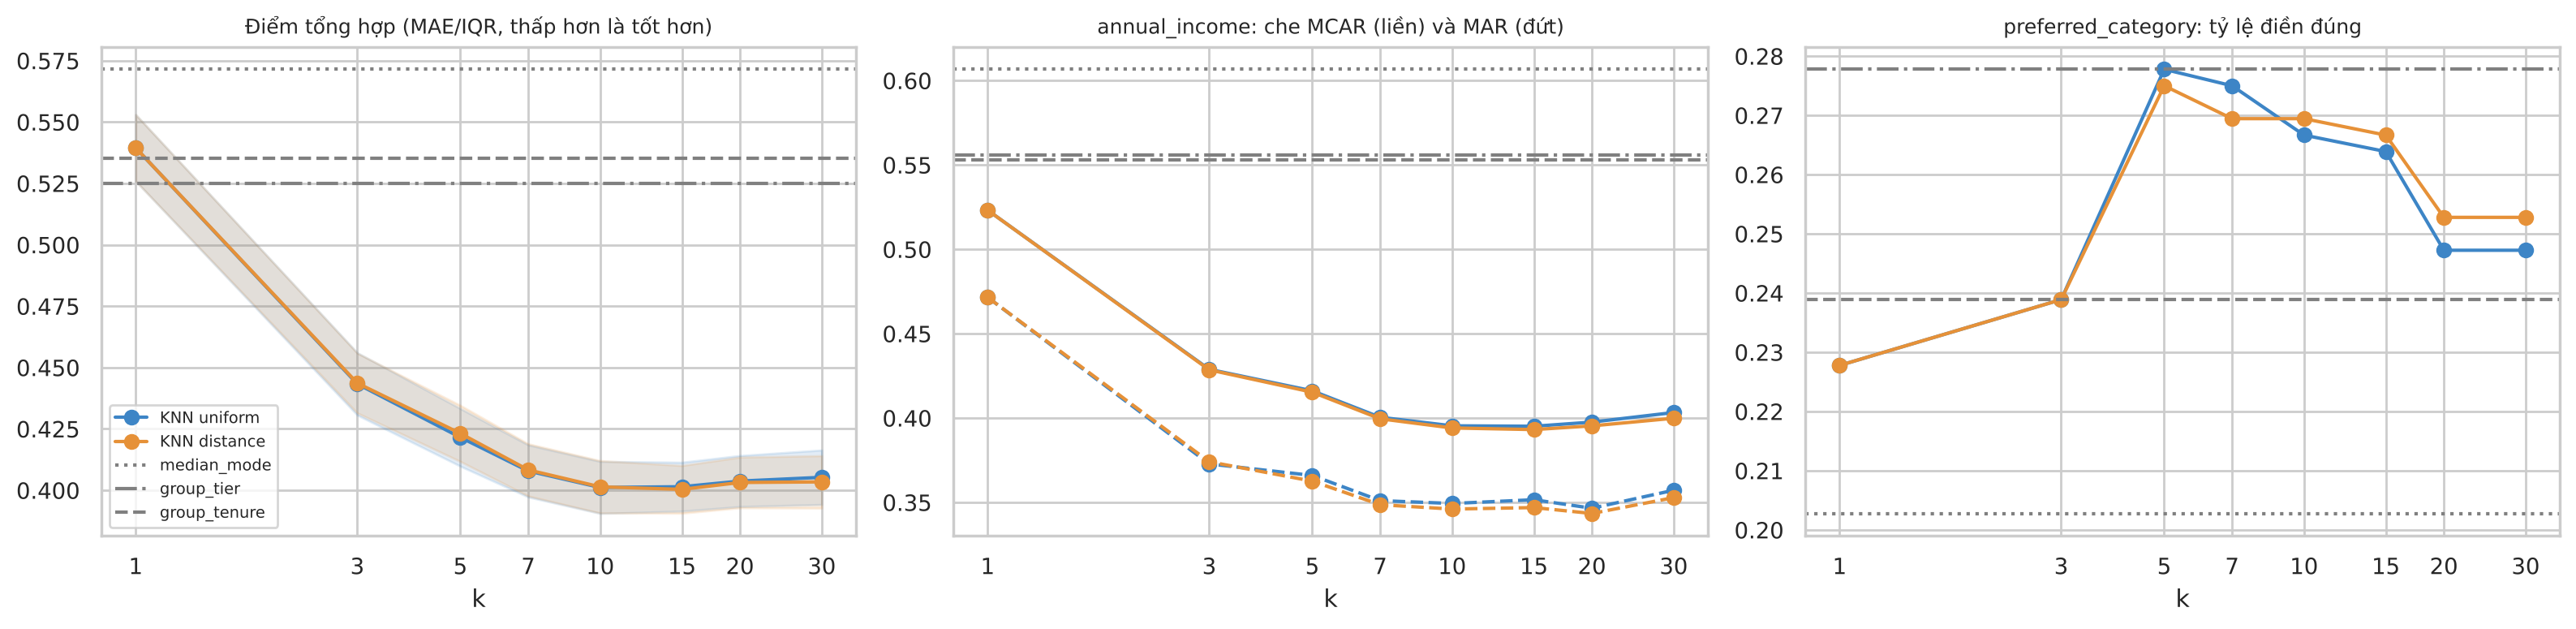

In [6]:
knn = summ[summ.index.str.startswith("knn")].copy()
knn["k"] = knn.index.str.extract(r"k(\d+)_")[0].astype(int).to_numpy()
knn["weights"] = knn.index.str.split("_").str[-1]
best = summ.iloc[0]
ok = knn[(knn.score <= best.score + best.se) & (knn.k <= 20)]
chosen = ok.sort_values(["k", "score"], ascending=[False, True]).index[0] if len(ok) else summ.index[0]
if not summ.index[0].startswith("knn"): chosen = summ.index[0]
print(f"Tot nhat: {summ.index[0]} (score {best.score:.4f} ± {best.se:.4f}) | Chon theo quy tac 1 SE: {chosen}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, t in [(axes[0], "score", "Điểm tổng hợp (MAE/IQR, thấp hơn là tốt hơn)"),
                   (axes[1], "income", "annual_income: che MCAR (liền) và MAR (đứt)"),
                   (axes[2], "category_acc", "preferred_category: tỷ lệ điền đúng")]:
    for w, color in [("uniform", "#3d85c6"), ("distance", "#e69138")]:
        s_ = knn[knn.weights == w].sort_values("k")
        ax.plot(s_.k, s_[col], "o-", color=color, label=f"KNN {w}")
        if col == "score": ax.fill_between(s_.k, s_[col] - s_.se, s_[col] + s_.se, color=color, alpha=.15)
        if col == "income": ax.plot(s_.k, s_.income_MAR, "o--", color=color)
    for m_, ls in [("median_mode", ":"), ("group_tier", "-."), ("group_tenure", "--")]:
        ax.axhline(summ.loc[m_, col], color="gray", ls=ls, label=m_)
    ax.set_xscale("log"); ax.set_xticks(K_GRID); ax.set_xticklabels(K_GRID); ax.set_xlabel("k"); ax.set_title(t, fontsize=9)
axes[0].legend(fontsize=7); fig.tight_layout(); savefig(fig, "c_mask_experiment.png"); plt.show()

**Nhận xét C4.**

- **KNN với k từ 7 đến 30 tốt hơn rõ các phương pháp đơn giản**: điểm khoảng 0,40 so với 0,57 của median/mode (giảm khoảng 30% sai số) và 0,53 của median theo nhóm. Với income, lợi thế giữ nguyên ở cả hai kiểu che (MCAR và ưu tiên tenure thấp).
- **k = 1 tệ gần bằng median chung** (0,54) và k = 3, 5 kém hơn k ≥ 7: đúng như lập luận về phương sai khi k nhỏ. **Giá trị mặc định k = 5 không phải lựa chọn tốt cho dữ liệu này** (0,42 so với 0,40).
- Đường sai số **phẳng từ k = 10 đến 30**; chênh lệch giữa các cấu hình trong vùng này nhỏ hơn 1 sai số chuẩn (khoảng 0,01), nên không thể nói k nào trong vùng đó "tốt nhất". Theo quy tắc 1 SE với giới hạn k ≤ 20, chọn **k = 20, trọng số theo khoảng cách**. Trọng số đều hay theo khoảng cách gần như không khác nhau.
- **`preferred_category` gần như không dự đoán được**: tỷ lệ điền đúng chỉ 20–28% với mọi phương pháp, tương đương tỷ lệ của lớp phổ biến nhất (26%). Các thuộc tính số không chứa đủ thông tin về ngành hàng ưa thích. Với 9 ô (4%), ảnh hưởng nhỏ, nhưng cần ghi nhận đây là phần điền kém tin cậy nhất; cột `imputed_cols` cho phép loại các ô này khi diễn giải cụm.

## C5. Điền giá trị thiếu bằng phương pháp đã chọn

In [7]:
imputed = METHODS[chosen](df)
imputed["imputed_cols"] = [",".join(need.columns[r]) for r in need.to_numpy()]
assert imputed[INPUT_COLS].isna().sum().sum() == 0 and len(imputed) == 220
assert check_constraints(imputed).sum() == 0
print("Phuong phap:", chosen, "| so o da dien:", int(need.sum().sum()), "| vi pham rang buoc sau xu ly:", int(check_constraints(imputed).sum()))
show = imputed.loc[invalid.any(axis=1), [ID_COL, "invalid_cols"]].copy()
show["gia_tri_sai"] = [dirty.loc[i, c] for i, c in zip(show.index, show.invalid_cols)]
show["gia_tri_dien"] = [imputed.loc[i, c] for i, c in zip(show.index, show.invalid_cols)]
show

Phuong phap: knn_k20_distance | so o da dien: 48 | vi pham rang buoc sau xu ly: 0


,customer_id,invalid_cols,gia_tri_sai,gia_tri_dien
110,C0111,return_rate,2.5,0.099
166,C0167,sessions_per_month,900.0,3.000
167,C0168,age,150.0,35.000
171,C0172,age,3.0,29.000
210,C0211,tenure_months,96.0,4.000
219,C0220,avg_order_value,-450.0,206.000


## C6. Nhiễu: thí nghiệm làm trơn bằng binning

Câu b kết luận nhiễu nhỏ, gần chuẩn, không tách được khỏi biến động tự nhiên ở từng giá trị. Thử **làm trơn theo trung bình bin** (equal-frequency) trên 3 cột số liên tục hoặc đếm có khả năng mang nhiễu đo lường: `sessions_per_month`, `avg_order_value`, `annual_income`, với 5, 10, 20 bin.

Tiêu chí đánh giá **không dùng dữ liệu sạch**:
- số giá trị phân biệt còn lại (mất độ phân giải);
- thay đổi trung bình của giá trị so với IQR;
- Spearman với thuộc tính liên quan (tín hiệu có được giữ không).

Lưu ý phương pháp: binning đơn biến thay mỗi giá trị bằng trung bình các giá trị **gần nó trên chính cột đó**, nên chỉ khử nhiễu được khi nhiễu lớn hơn độ rộng bin; nó không dùng thông tin từ thuộc tính khác để biết giá trị nào bị lệch.

In [8]:
def bin_smooth(x, n_bins):
    b = pd.qcut(x.rank(method="first"), n_bins, labels=False)
    return x.groupby(b).transform("mean")

PAIR = {"sessions_per_month": "orders_per_year", "avg_order_value": "annual_income", "annual_income": "avg_order_value"}
smoothed = {}; rows = []
for col, other in PAIR.items():
    x = imputed[col]; iqr = x.quantile(.75) - x.quantile(.25)
    rows.append({"cot": col, "n_bins": "khong lam tron", "so_gia_tri_khac": x.nunique(), "thay_doi_TB/IQR": 0.0,
                 "spearman_voi_cot_lien_quan": stats.spearmanr(x, imputed[other])[0]})
    for nb_ in (5, 10, 20):
        s_ = bin_smooth(x, nb_); smoothed[(col, nb_)] = s_
        rows.append({"cot": col, "n_bins": nb_, "so_gia_tri_khac": s_.nunique(),
                     "thay_doi_TB/IQR": (s_ - x).abs().mean() / iqr,
                     "spearman_voi_cot_lien_quan": stats.spearmanr(s_, imputed[other])[0]})
c6 = pd.DataFrame(rows); c6.to_csv(TABLES / "c6_binning_internal.csv", index=False)
c6.round(4)

,cot,n_bins,so_gia_tri_khac,thay_doi_TB/IQR,spearman_voi_cot_lien_quan
0,sessions_per_month,khong lam tron,61,0.0000,0.8963
1,sessions_per_month,5,5,0.2877,0.8745
2,sessions_per_month,10,10,0.2009,0.8888
3,sessions_per_month,20,20,0.1330,0.8930
4,avg_order_value,khong lam tron,219,0.0000,0.7643
5,avg_order_value,5,5,2.2285,0.7484
6,avg_order_value,10,10,1.9588,0.7575
7,avg_order_value,20,20,1.6026,0.7635
8,annual_income,khong lam tron,212,0.0000,0.7643
9,annual_income,5,5,0.6659,0.7521


**Nhận xét C6 (trước khi đối chiếu).** Binning làm mất độ phân giải nghiêm trọng (214–219 giá trị phân biệt còn 5–20) và thay đổi giá trị rất lớn: với avg_order_value, thay đổi trung bình bằng 1,6–2,2 lần IQR, vì bin cao nhất gộp khách thường với các khách cực trị và kéo trung bình bin lên. Spearman với thuộc tính liên quan không tăng (giảm nhẹ). Không có dấu hiệu nội tại nào cho thấy làm trơn giúp ích, trong khi mất thông tin là chắc chắn. **Quyết định: không áp dụng binning vào dữ liệu đầu ra.** Nhiễu được xử lý gián tiếp ở câu d (log, chuẩn hóa, giảm chiều). Quyết định này được kiểm chứng ở C8.

## C7. Phân tích sự thay đổi của dữ liệu sau tiền xử lý

In [9]:
final = imputed.copy()
final[INT_COLS] = final[INT_COLS].astype(int)
out_cols = [ID_COL] + INPUT_COLS + ["outlier_type", "invalid_cols", "imputed_cols"]
final[out_cols].to_csv(PROCESSED / "customers_preprocessed.csv", index=False, encoding="utf-8-sig")

before, after = dirty[NUM_COLS].astype(float), final[NUM_COLS].astype(float)
chg = pd.DataFrame({
    "n_truoc": before.count(), "n_sau": after.count(),
    "mean_truoc": before.mean(), "mean_sau": after.mean(),
    "median_truoc": before.median(), "median_sau": after.median(),
    "std_truoc": before.std(), "std_sau": after.std(),
    "skew_truoc": before.skew(), "skew_sau": after.skew(),
    "min_sau": after.min(), "max_sau": after.max()})
chg.to_csv(TABLES / "c7_before_after.csv")
print("So dong:", len(dirty), "->", len(final), "| o thieu:", int(dirty[INPUT_COLS].isna().sum().sum()), "->",
      int(final[INPUT_COLS].isna().sum().sum()), "| vi pham rang buoc cung:",
      int(check_constraints(dirty).sum()), "->", int(check_constraints(final).sum()))
chg.round(3)

So dong: 220 -> 220 | o thieu: 42 -> 0 | vi pham rang buoc cung: 6 -> 0


,n_truoc,n_sau,mean_truoc,mean_sau,median_truoc,median_sau,std_truoc,std_sau,skew_truoc,skew_sau,min_sau,max_sau
age,209,220,32.407,31.936,31.000,31.000,12.098,8.570,4.482,0.415,18.000,60.000
tenure_months,220,220,32.577,32.159,22.000,22.000,32.666,32.439,1.457,1.489,1.000,158.000
annual_income,198,220,330.218,318.311,211.500,202.900,535.972,510.391,6.964,7.316,78.100,4967.000
orders_per_year,220,220,30.036,30.036,23.000,23.000,40.440,40.440,4.863,4.863,1.000,326.000
avg_order_value,220,220,1064.502,1067.484,399.750,399.750,3903.667,3902.756,8.074,8.077,124.500,35875.800
days_since_last_purchase,220,220,63.959,63.959,16.500,16.500,94.931,94.931,1.925,1.925,0.000,365.000
return_rate,220,220,0.134,0.123,0.104,0.102,0.180,0.081,10.544,0.796,0.001,0.369
discount_usage_rate,220,220,0.456,0.456,0.434,0.434,0.230,0.230,0.229,0.229,0.059,0.940
sessions_per_month,220,220,26.486,22.409,17.500,17.000,63.599,23.378,12.094,3.640,0.000,198.000


In [10]:
key = [("orders_per_year", "sessions_per_month"), ("annual_income", "avg_order_value"),
       ("orders_per_year", "days_since_last_purchase"), ("age", "tenure_months")]
c7c = pd.DataFrame([{"cap": f"{x} – {y}",
                     "pearson_truoc": before[x].corr(before[y]), "pearson_sau": after[x].corr(after[y]),
                     "spearman_truoc": before[x].corr(before[y], "spearman"),
                     "spearman_sau": after[x].corr(after[y], "spearman")} for x, y in key])
print(pd.crosstab(dirty.preferred_category.fillna("(thiếu)"), "truoc").join(pd.crosstab(final.preferred_category, "sau")).fillna(0).astype(int).T)
c7c.round(3)

preferred_category  (thiếu)  Gia dụng  Mỹ phẩm  Thời trang  Thực phẩm  Điện tử
col_0                                                                         
truoc                     9        37       31          55         35       53
sau                       0        37       31          60         36       56


,cap,pearson_truoc,pearson_sau,spearman_truoc,spearman_sau
0,orders_per_year – sessions_per_month,0.290,0.902,0.879,0.896
1,annual_income – avg_order_value,0.972,0.972,0.771,0.764
2,orders_per_year – days_since_last_purchase,-0.323,-0.323,-0.659,-0.659
3,age – tenure_months,0.339,0.343,0.342,0.350


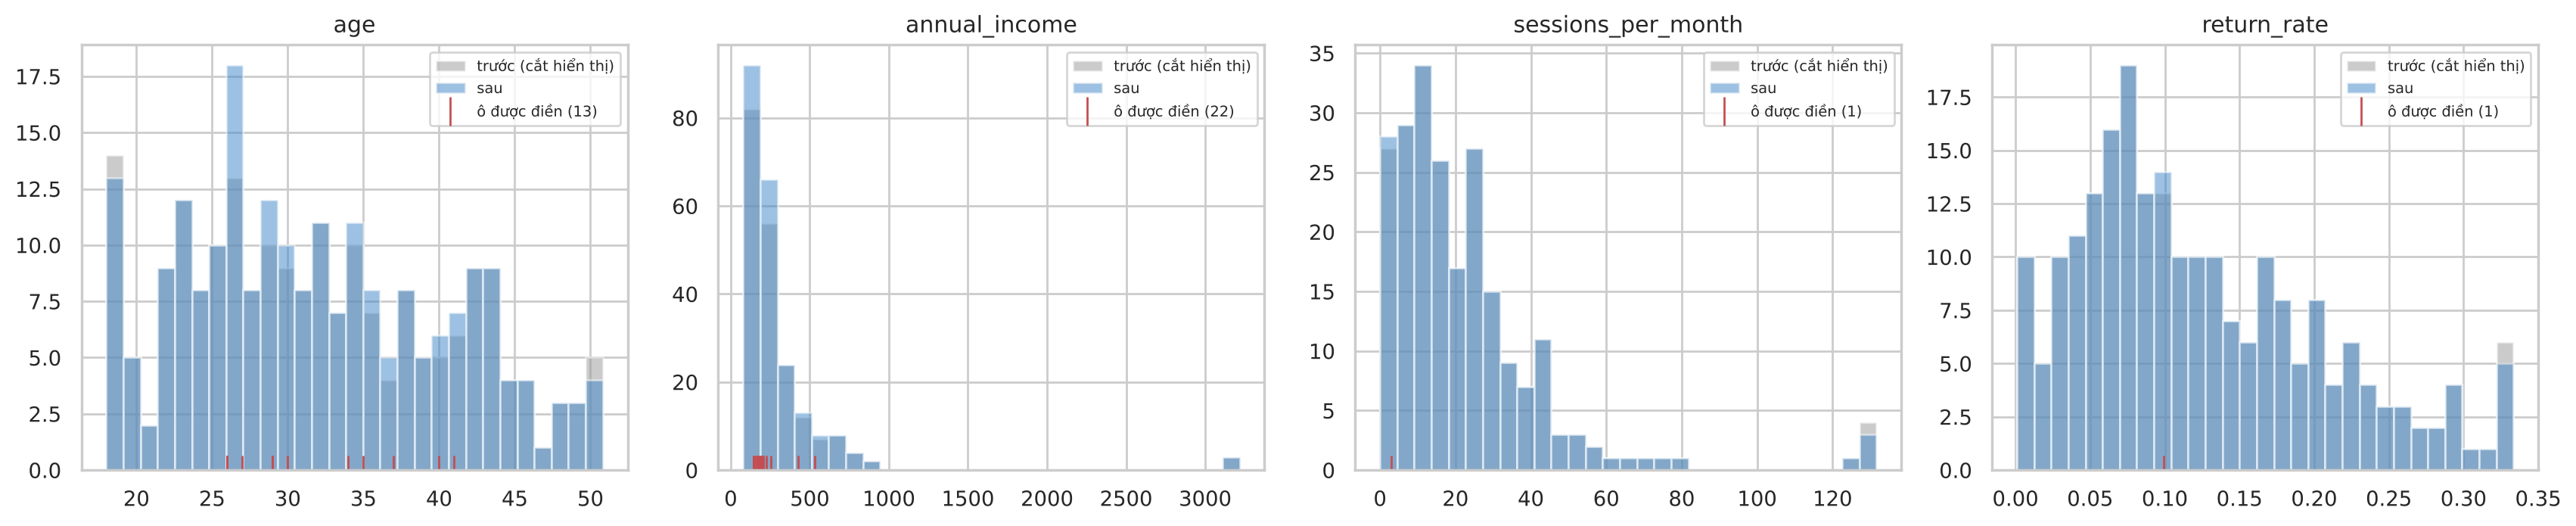

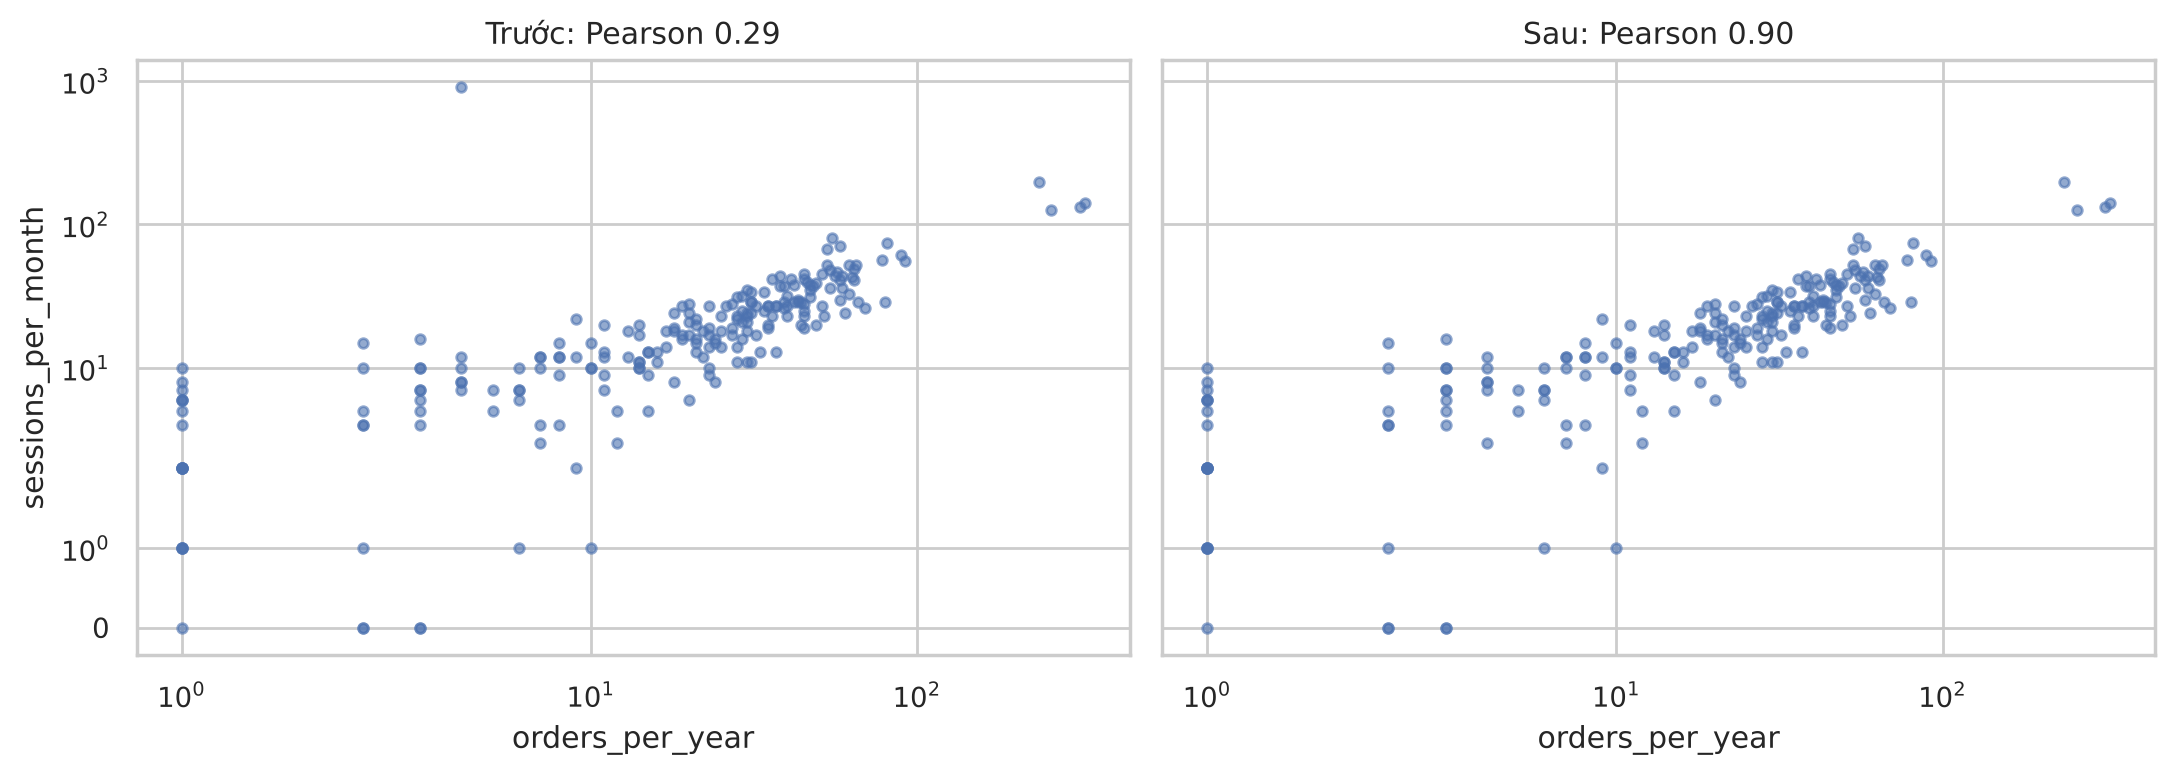

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col in zip(axes, ["age", "annual_income", "sessions_per_month", "return_rate"]):
    lo, hi = after[col].quantile([0, .99]); bins = np.linspace(lo, hi, 30)
    ax.hist(before[col].dropna().clip(lo, hi), bins=bins, alpha=.5, color="#999999", label="trước (cắt hiển thị)")
    ax.hist(after[col].clip(lo, hi), bins=bins, alpha=.5, color="#3d85c6", label="sau")
    m = need[col]
    ax.plot(after.loc[m, col].clip(lo, hi), np.zeros(m.sum()), "r|", ms=14, label=f"ô được điền ({m.sum()})")
    ax.set_title(col); ax.legend(fontsize=7)
fig.tight_layout(); savefig(fig, "c_before_after_hist.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, d, t in [(axes[0], before, "Trước"), (axes[1], after, "Sau")]:
    ax.scatter(d.orders_per_year, d.sessions_per_month, s=12, alpha=.6)
    ax.set_xscale("symlog"); ax.set_yscale("symlog"); ax.set_xlabel("orders_per_year")
    ax.set_title(f"{t}: Pearson {d.orders_per_year.corr(d.sessions_per_month):.2f}")
axes[0].set_ylabel("sessions_per_month"); fig.tight_layout(); savefig(fig, "c_scatter_before_after.png"); plt.show()

**Nhận xét C7.**

- **Số dòng giữ nguyên 220**; ô thiếu 42 → 0; vi phạm ràng buộc cứng 6 → 0.
- **Các thống kê nhạy với ngoại lai thay đổi mạnh chỉ nhờ sửa 6 ô**: std của sessions từ 63,6 xuống 23,4 và skewness từ 12,1 xuống 3,6; std của return_rate từ 0,180 xuống 0,081, skewness từ 10,5 xuống 0,8; skewness của age từ 4,5 xuống 0,4. Median hầu như không đổi, khẳng định lại median là thước đo bền vững.
- **Pearson orders – sessions hồi phục từ 0,29 lên 0,90**, gần bằng Spearman (0,90); Spearman gần như không đổi (0,879 → 0,896). Đây là bằng chứng trực tiếp rằng một ô sai làm hỏng Pearson.
- **income, AOV, orders vẫn lệch rất mạnh** (skewness 7,3; 8,1; 4,9) và Pearson income – AOV vẫn 0,97, do các cực trị hợp lý được giữ nguyên có chủ đích. Đây là việc còn lại cho câu d.
- Mean của income giảm nhẹ (330 → 318) vì các giá trị được điền nằm ở vùng thấp, phù hợp với nhận định câu b rằng income thiếu tập trung ở khách mới.
- preferred_category: 9 ô thiếu được phân vào Thời trang (+5), Điện tử (+3), Thực phẩm (+1); tỷ lệ các lớp thay đổi không đáng kể.

## C8. Đối chiếu với dữ liệu sạch (chỉ để đánh giá)

Giá trị "thật" của một ô là giá trị trong dữ liệu sạch. Với các cột có nhiễu, phương pháp điền không thể biết phần nhiễu, nên sai số có một phần không thể giảm.

In [12]:
clean = load_raw("customers_clean"); log = load_raw("injection_log")
cl = clean[INPUT_COLS]
IQRC = clean[NUM_COLS].quantile(.75) - clean[NUM_COLS].quantile(.25)
rows = []
for name, f in METHODS.items():
    out = f(df); r = {"method": name}
    for c in ["age", "annual_income"]:
        m = orig_missing[c]; r[f"{c}_MAE"] = (out.loc[m, c] - cl.loc[m, c]).abs().mean()
    m = orig_missing.preferred_category
    r["category_acc"] = (out.loc[m, "preferred_category"] == cl.loc[m, "preferred_category"]).mean()
    r["score_thieu_goc"] = np.average([r["age_MAE"] / IQRC["age"], r["annual_income_MAE"] / IQRC["annual_income"]], weights=[11, 22])
    e = [abs(out.loc[i, c] - cl.loc[i, c]) / IQRC[c] for c in NUM_COLS for i in invalid.index[invalid[c]]]
    r["score_o_bat_kha"] = np.mean(e)
    rows.append(r)
c8 = pd.DataFrame(rows).set_index("method")
c8["hang_that"] = c8.score_thieu_goc.rank().astype(int)
c8["hang_C4"] = summ.score.rank().astype(int).reindex(c8.index)
c8.to_csv(TABLES / "c8_imputation_vs_clean.csv")
print("Phuong phap da chon:", chosen, "| tuong quan hang (C4 so voi that):",
      round(stats.spearmanr(c8.hang_that, c8.hang_C4)[0], 3))
c8.sort_values("score_thieu_goc").round(4)

Phuong phap da chon: knn_k20_distance | tuong quan hang (C4 so voi that): 0.884


,age_MAE,annual_income_MAE,category_acc,score_thieu_goc,score_o_bat_kha,hang_that,hang_C4
method,,,,,,,
knn_k20_uniform,3.3636,72.9500,0.4444,0.3634,0.2308,1,7
knn_k20_distance,3.4545,72.4455,0.4444,0.3637,0.2235,2,5
knn_k15_distance,3.5455,72.8227,0.4444,0.3674,0.2253,3,1
knn_k15_uniform,3.6364,73.5045,0.4444,0.3723,0.2191,4,4
knn_k10_uniform,3.5455,75.3636,0.6667,0.3772,0.2316,5,2
knn_k10_distance,3.6364,75.0591,0.6667,0.3783,0.2308,6,3
knn_k30_distance,3.8182,75.8818,0.5556,0.3860,0.1995,7,6
knn_k30_uniform,3.7273,77.1227,0.5556,0.3885,0.2005,8,8
knn_k3_distance,4.3636,76.6273,0.4444,0.4026,0.2132,9,14


In [13]:
# Tung o bat kha: gia tri sai, gia tri dien, gia tri that
rows = []
for c in INPUT_COLS:
    for i in invalid.index[invalid[c]]:
        rows.append({ID_COL: final.at[i, ID_COL], "cot": c, "gia_tri_sai": dirty.at[i, c],
                     "gia_tri_dien": final.at[i, c], "gia_tri_that": clean.at[i, c]})
pd.DataFrame(rows)

,customer_id,cot,gia_tri_sai,gia_tri_dien,gia_tri_that
0,C0168,age,150.0,35.000,27.000
1,C0172,age,3.0,29.000,30.000
2,C0211,tenure_months,96.0,4.000,11.000
3,C0220,avg_order_value,-450.0,206.000,124.800
4,C0111,return_rate,2.5,0.099,0.084
5,C0167,sessions_per_month,900.0,3.000,6.000


In [14]:
# Sai so dien income theo phan khuc that (kiem tra anh huong cua MAR)
m = orig_missing.annual_income
e = pd.DataFrame({"seg": clean.true_segment[m], "that": cl.annual_income[m], "dien": final.annual_income[m],
                  "median_chung": dirty.annual_income.median()})
e["sai_so_da_chon"] = (e.dien - e.that).abs(); e["sai_so_median"] = (e.median_chung - e.that).abs()
print("Sai lech co huong (dien - that), trung binh:", round((e.dien - e.that).mean(), 1),
      "| voi median chung:", round((e.median_chung - e.that).mean(), 1))
e.groupby("seg").agg(n=("that", "size"), that_TB=("that", "mean"), dien_TB=("dien", "mean"),
                     MAE_da_chon=("sai_so_da_chon", "mean"), MAE_median=("sai_so_median", "mean")).round(1)

Sai lech co huong (dien - that), trung binh: -44.0 | voi median chung: -43.7


,n,that_TB,dien_TB,MAE_da_chon,MAE_median
seg,,,,,
DealHunter,5,159.4,150.9,8.5,52.1
Loyal,1,292.5,252.3,40.2,81.0
NewInactive,14,213.3,191.5,66.4,68.6
VIP,2,769.5,478.6,291.0,558.0


In [15]:
# Binning: co dua du lieu ve gan gia tri that hon khong? (cac dong khong bi cai ngoai lai)
out_ids = log[log.kind.str.startswith("outlier")].customer_id.unique()
keep = ~final[ID_COL].isin(out_ids)
rows = []
for col in PAIR:
    base = (final.loc[keep, col] - clean.loc[keep, col]).abs().mean()
    r = {"cot": col, "MAE_khong_lam_tron": base}
    for nb_ in (5, 10, 20):
        r[f"MAE_{nb_}_bin"] = (smoothed[(col, nb_)][keep] - clean.loc[keep, col]).abs().mean()
    rows.append(r)
c8b = pd.DataFrame(rows).set_index("cot"); c8b.to_csv(TABLES / "c8_binning_vs_clean.csv")
c8b.round(3)

,MAE_khong_lam_tron,MAE_5_bin,MAE_10_bin,MAE_20_bin
cot,,,,
sessions_per_month,1.620,4.722,3.425,2.747
avg_order_value,37.255,486.991,394.727,223.891
annual_income,16.928,69.449,59.402,49.393


In [16]:
# Muc do gan voi du lieu sach truoc va sau tien xu ly (tat ca dong, thuoc tinh so)
def dist_to_clean(d):
    x = d[NUM_COLS].astype(float); return ((x - clean[NUM_COLS]).abs() / IQRC)
b_, a_ = dist_to_clean(dirty), dist_to_clean(final)
pd.DataFrame({"truoc (bo qua o thieu)": b_.mean(), "sau": a_.mean(),
              "sau, bo cac dong ngoai lai logic va hop le (gia tri co y khac ban sach)": a_[keep | final.invalid_cols.ne("")].mean()}).round(4)

,truoc (bo qua o thieu),sau,"sau, bo cac dong ngoai lai logic va hop le (gia tri co y khac ban sach)"
age,0.0542,0.0161,0.0168
tenure_months,0.0094,0.0008,0.0008
annual_income,0.3843,0.3874,0.0956
orders_per_year,0.1635,0.1635,0.0000
avg_order_value,1.3327,1.3268,0.0959
days_since_last_purchase,0.0206,0.0206,0.0000
return_rate,0.0974,0.0006,0.0006
discount_usage_rate,0.0000,0.0000,0.0000
sessions_per_month,0.4022,0.2022,0.0821


**Nhận xét C8 (đối chiếu).**

*Được xác nhận:*
- **Thí nghiệm che rồi điền lại chọn đúng hướng**: tương quan hạng giữa xếp hạng ở C4 và xếp hạng theo sai số thật là 0,88. Phương pháp đã chọn (KNN k = 20, trọng số khoảng cách) đứng thứ 2/19 theo sai số thật; MAE của age là 3,5 tuổi (median chung: 7,2) và của income là 72,4 (median chung: 109,9), giảm khoảng 34–52%.
- **Binning làm dữ liệu xa giá trị thật hơn ở mọi cấu hình**: sai số của sessions tăng 1,7–2,9 lần, income 2,9–4,1 lần, AOV 6–13 lần. Quyết định không làm trơn ở C6 là đúng. Lý do: nhiễu (5–8% giá trị) nhỏ hơn nhiều so với độ rộng bin, nên binning xóa biến động thật giữa các khách nhiều hơn là khử nhiễu.
- 6 ô bất khả được điền khá sát giá trị thật: tuổi 29 so với 30 và 35 so với 27; return_rate 0,099 so với 0,084; sessions 3 so với 6; tenure 4 so với 11; AOV 206 so với 125.
- Sau tiền xử lý, khoảng cách trung bình tới dữ liệu sạch giảm ở các cột được sửa: sessions từ 0,40 xuống 0,20 IQR; return_rate từ 0,097 xuống 0,0006; age từ 0,054 xuống 0,016.

*Hạn chế, cần ghi nhận:*
1. **Giá trị income được điền vẫn thấp hơn thật một cách có hệ thống** (trung bình −44, tương đương điền median chung), dù sai số tuyệt đối nhỏ hơn. Nguyên nhân chính là 2 khách VIP thiếu income (thật 770, điền 479): với k = 20 và nhóm VIP nhỏ, láng giềng của họ lẫn cả khách không phải VIP. Đây chính là đánh đổi của k lớn đã nêu khi chọn k. Với 14 khách NewInactive, KNN gần như không tốt hơn median (MAE 66 so với 69).
2. **Sự phẳng của đường sai số khiến việc chọn k cụ thể không chắc chắn**: theo sai số thật, k = 20 tốt nhất, nhưng C4 xếp k = 15 và 10 lên trước. Kết luận vững là "k trong khoảng 10–20", không phải một giá trị duy nhất.
3. `preferred_category`: đúng 4/9 ô; 9 ô là quá ít để so sánh phương pháp.
4. Khoảng cách tới dữ liệu sạch của income, AOV, orders không giảm ở mức toàn bộ dữ liệu, vì các ngoại lai hợp lệ và đáng ngờ được giữ nguyên có chủ đích (giá trị của chúng khác bản sạch theo thiết kế). Phần nhiễu còn lại tương đương 0,08–0,10 IQR và không bị loại bỏ.

## Tóm tắt câu c

| Vấn đề | Xử lý | Cơ sở lựa chọn | Kết quả |
|---|---|---|---|
| 6 ô bất khả | Đặt NaN, điền lại, gắn cờ `invalid_cols` | Giá trị sai không mang thông tin; giữ 12 ô đúng còn lại của dòng | 0 vi phạm ràng buộc; giá trị điền sát thật |
| 3 dòng đáng ngờ | Giữ, gắn cờ | Không phân biệt được với hành vi thật (câu b) | Giữ nguyên |
| 17 cực trị hợp lý | Giữ, gắn cờ | Khách giá trị cao thật; không mặc định loại bỏ | Giữ nguyên; xử lý thang đo ở câu d |
| 42 ô thiếu | KNN, k = 20, trọng số khoảng cách | Thí nghiệm che rồi điền lại trên dữ liệu bẩn: sai số thấp hơn median khoảng 30% | Đối chiếu: đứng 2/19; giảm 34–52% sai số so với median |
| Nhiễu | Không làm trơn | Thí nghiệm binning: mất độ phân giải, không tăng tín hiệu | Đối chiếu: binning tăng sai số 1,7–13 lần |

**Sản phẩm:** `data/processed/customers_preprocessed.csv`: 220 dòng, `customer_id`, 13 thuộc tính đã làm sạch trên thang gốc, và 3 cột metadata (`outlier_type`, `invalid_cols`, `imputed_cols`) không dùng làm đặc trưng. Không chứa `true_segment`.

**Việc còn lại cho câu d:** chênh lệch thang đo; độ lệch mạnh của income, AOV, orders; thuộc tính dư thừa; mã hóa thuộc tính danh mục; thuộc tính không mang cấu trúc cụm (gender, region).